Notebook that creates figures that compare halo, cloud, uniform sampling

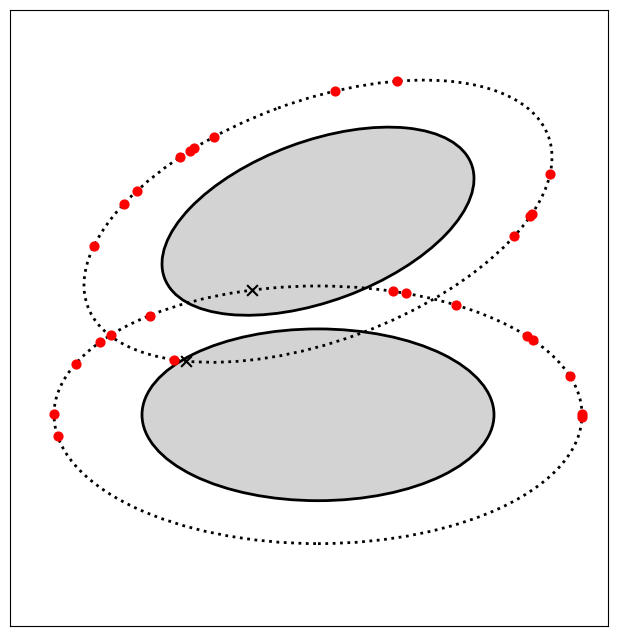

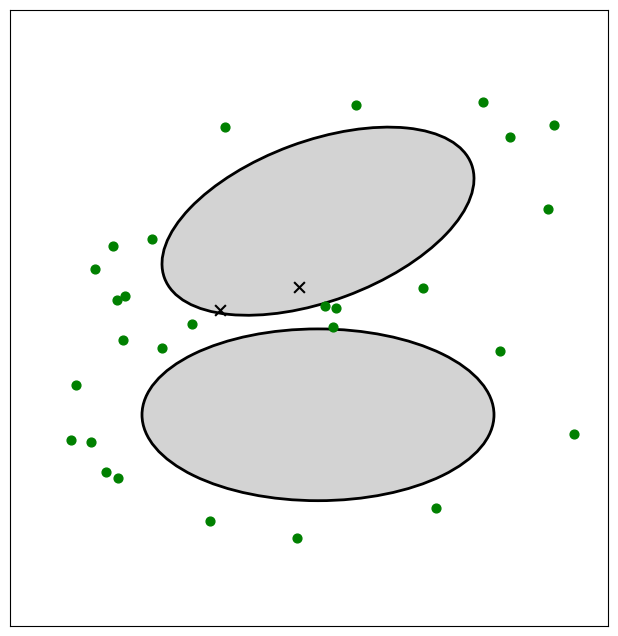

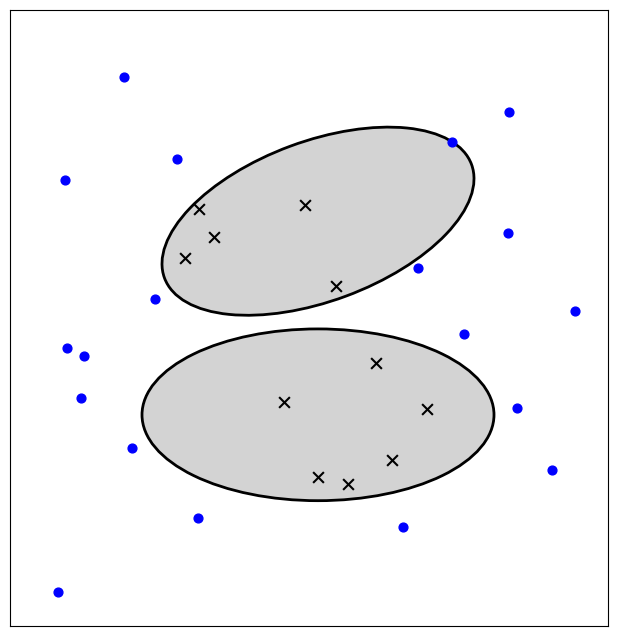

In [ ]:
from matplotlib.patches import Ellipse
import numpy as np
import matplotlib.pyplot as plt

def compute_ellipse_object(T, c, color="black"):
    eigvals, eigvecs = np.linalg.eigh(T)
    axes = 1 / np.sqrt(eigvals)
    width = 2 * axes[0]
    height = 2 * axes[1]
    angle = np.degrees(np.arctan2(eigvecs[1,0], eigvecs[0,0]))
    return Ellipse(
        xy = c,
        width = width,
        height = height,
        angle = angle,
        fill = True,
        edgecolor = "black",
        facecolor = color,
        linewidth = 2
    )

def compute_halo_region(T, c, gamma):
    eigvals, eigvecs = np.linalg.eigh(T)
    axes = 1 / np.sqrt(eigvals)
    width = 2 * gamma * axes[0]
    height = 2 * gamma * axes[1]
    angle = np.degrees(np.arctan2(eigvecs[1,0], eigvecs[0,0]))
    return Ellipse(
        xy = c,
        width = width,
        height = height,
        angle = angle,
        fill = False,
        edgecolor = "black",
        linewidth = 2,
        linestyle = ":"
    )

def _generate_halo_points(T, c, gamma, n):
    eigvals, eigvecs = np.linalg.eigh(T)
    theta = np.random.uniform(0, 2*np.pi, n)
    points = np.vstack([
        np.cos(theta),
        np.sin(theta)
    ])
    return c[:,None] + gamma * eigvecs * (eigvals ** (-0.5)) @ points

def _generate_cloud_points_1(T, c, n):
    eigvals, eigvecs = np.linalg.eigh(T)
    points = np.random.randn(2, n)
    return c[:,None] + eigvecs * (eigvals ** (-0.5)) @ points

def _generate_cloud_points_2(T, c, n):
    eigvals, eigvecs = np.linalg.eigh(T)
    theta = np.random.uniform(0, 2*np.pi, n)
    points = np.vstack([
        np.cos(theta),
        np.sin(theta)
    ])
    gamma = 1.4 + 0.15 * np.random.randn(n)
    return c[:,None] + eigvecs * (eigvals ** (-0.5)) @ (gamma * points)

def _generate_uniform_points(n):
    xpad = 0.05 * (rx-lx); ypad = 0.05 * (ry-ly)
    x = np.random.uniform(low=lx+xpad, high=rx-xpad, size=n)
    y = np.random.uniform(low=ly+ypad, high=ry-ypad, size=n)
    return np.vstack((x, y))

def _check_in_trust_region(T, c, X):
    X_scaled = X - c[:,None]
    mask = np.einsum("in,ij,jn->n", X_scaled, T, X_scaled) <= 1
    return mask
    

def create_halo_figure(gamma = 1.5, color="red", savepng=True):

    fig, ax = plt.subplots(figsize=(8,8))
    ax.add_patch(compute_ellipse_object(T1, c1, "lightgrey"))
    ax.add_patch(compute_ellipse_object(T2, c2, "lightgrey"))
    ax.add_patch(compute_halo_region(T1, c1, gamma))
    ax.add_patch(compute_halo_region(T2, c2, gamma))

    # Sample a few points on the halo boundary
    halo_1 = _generate_halo_points(T1, c1, gamma, 15)
    halo_2 = _generate_halo_points(T2, c2, gamma, 15)
    halo_1_in_2 = _check_in_trust_region(T2, c2, halo_1)
    halo_2_in_1 = _check_in_trust_region(T1, c1, halo_2)
    ax.scatter(halo_1[0,halo_1_in_2], halo_1[1,halo_1_in_2], s=60, c="black", marker="x")
    ax.scatter(halo_1[0,~halo_1_in_2], halo_1[1,~halo_1_in_2], s=40, c=color)
    ax.scatter(halo_2[0,halo_2_in_1], halo_2[1,halo_2_in_1], s=60, c="black", marker="x")
    ax.scatter(halo_2[0,~halo_2_in_1], halo_2[1,~halo_2_in_1], s=40, c=color)

    ax.set_xlim(lx, rx)
    ax.set_ylim(ly, ry)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(True)
    ax.margins(0)

    if savepng:
        fig.savefig("figs/halo.png")
    else:
        plt.show()


def create_cloud_figure_1(color="green", savepng=True):

    fig, ax = plt.subplots(figsize=(8,8))
    ax.add_patch(compute_ellipse_object(T1, c1, "lightgrey"))
    ax.add_patch(compute_ellipse_object(T2, c2, "lightgrey"))

    # Sample a few points on the halo boundary
    cloud_1 = _generate_cloud_points_1(T1, c1, 15)
    cloud_2 = _generate_cloud_points_1(T2, c2, 15)
    cloud_1_in_2 = _check_in_trust_region(T2, c2, cloud_1)
    cloud_1_in_1 = _check_in_trust_region(T1, c1, cloud_1)
    cloud_2_in_1 = _check_in_trust_region(T1, c1, cloud_2)
    cloud_2_in_2 = _check_in_trust_region(T2, c2, cloud_2)
    cloud_1_in_tr = cloud_1_in_1 | cloud_1_in_2
    cloud_2_in_tr = cloud_2_in_1 | cloud_2_in_2
    ax.scatter(cloud_1[0,cloud_1_in_tr], cloud_1[1,cloud_1_in_tr], s=60, c="black", marker="x")
    ax.scatter(cloud_1[0,~cloud_1_in_tr], cloud_1[1,~cloud_1_in_tr], s=40, c=color)
    ax.scatter(cloud_2[0,cloud_2_in_tr], cloud_2[1,cloud_2_in_tr], s=60, c="black", marker="x")
    ax.scatter(cloud_2[0,~cloud_2_in_tr], cloud_2[1,~cloud_2_in_tr], s=40, c=color)

    ax.set_xlim(lx, rx)
    ax.set_ylim(ly, ry)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(True)
    ax.margins(0)

    if savepng:
        fig.savefig("figs/cloud.png")
    else:
        plt.show()
    

# NOTE: this is not truly cloud sampling, but it looks really bad
# if we don't do it like this.
def create_cloud_figure_2(color="green", savepng = True):

    fig, ax = plt.subplots(figsize=(8,8))
    ax.add_patch(compute_ellipse_object(T1, c1, "lightgrey"))
    ax.add_patch(compute_ellipse_object(T2, c2, "lightgrey"))

    # Sample a few points on the halo boundary
    cloud_1 = _generate_cloud_points_2(T1, c1, 15)
    cloud_2 = _generate_cloud_points_2(T2, c2, 15)
    cloud_1_in_2 = _check_in_trust_region(T2, c2, cloud_1)
    cloud_1_in_1 = _check_in_trust_region(T1, c1, cloud_1)
    cloud_2_in_1 = _check_in_trust_region(T1, c1, cloud_2)
    cloud_2_in_2 = _check_in_trust_region(T2, c2, cloud_2)
    cloud_1_in_tr = cloud_1_in_1 | cloud_1_in_2
    cloud_2_in_tr = cloud_2_in_1 | cloud_2_in_2
    ax.scatter(cloud_1[0,cloud_1_in_tr], cloud_1[1,cloud_1_in_tr], s=60, c="black", marker="x")
    ax.scatter(cloud_1[0,~cloud_1_in_tr], cloud_1[1,~cloud_1_in_tr], s=40, c=color)
    ax.scatter(cloud_2[0,cloud_2_in_tr], cloud_2[1,cloud_2_in_tr], s=60, c="black", marker="x")
    ax.scatter(cloud_2[0,~cloud_2_in_tr], cloud_2[1,~cloud_2_in_tr], s=40, c=color)

    ax.set_xlim(lx, rx)
    ax.set_ylim(ly, ry)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(True)
    ax.margins(0)

    if savepng:
        fig.savefig("figs/cloud.png")
    else:
        plt.show()


def create_uniform_figure(color="blue", savepng = True):

    fig, ax = plt.subplots(figsize=(8,8))
    ax.add_patch(compute_ellipse_object(T1, c1, "lightgrey"))
    ax.add_patch(compute_ellipse_object(T2, c2, "lightgrey"))

    # Sample a few points on the halo boundary
    unif_1 = _generate_uniform_points(30)
    unif_1_in_1 = _check_in_trust_region(T1, c1, unif_1)
    unif_1_in_2 = _check_in_trust_region(T2, c2, unif_1)
    unif_in_tr = unif_1_in_1 | unif_1_in_2
    ax.scatter(unif_1[0,unif_in_tr], unif_1[1,unif_in_tr], s=60, c="black", marker="x")
    ax.scatter(unif_1[0,~unif_in_tr], unif_1[1,~unif_in_tr], s=40, c=color)

    ax.set_xlim(lx, rx)
    ax.set_ylim(ly, ry)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(True)
    ax.margins(0)

    if savepng:
        fig.savefig("figs/uniform.png")
    else:
        plt.show()


# Define ellipses for plotting
T1 = np.array([[0.4, -0.3], [-0.3, 1.1]]); c1 = np.array([0.2, 1.1])
T2 = np.array([[0.25, 0], [0, 1.05]]); c2 = np.array([0.2, -1.1])
lx = -3.3; rx = 3.5;
ly = -3.5; ry = 3.5;


create_halo_figure()
create_cloud_figure_2()
create_uniform_figure()